# PathSnap: final backend demonstration
This is an editable Jupyter notebook with actual executed outputs.
The first cells show the original five-model comparison. Later cells show
completed Bayesian optimisation, student-test HMM results, frozen-model
provenance, final evaluator outputs, and a live backend request.
Reference routes remain on this backend laptop. No evaluator data was used
to fit, tune or select the model. Pointwise scores remain alignment proxies.

## Setup
Use the project `.venv` Python kernel. In VS Code, open this notebook, choose
**Select Kernel → Python Environments → .venv**, then **Run All**.
The saved figures and tables are already visible without running cells.

In [1]:
from pathlib import Path
import sys, os, json
root_candidates = [Path.cwd(), Path.cwd().parent]
ROOT = next(p for p in root_candidates if (p / 'artifacts/model_comparison.csv').exists())
os.environ['MPLCONFIGDIR'] = str(ROOT / '.cache/matplotlib')
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'tools'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from show_outputs import fresh_predictions, comparison_figures, confusion_figure, NAMES
pd.set_option('display.max_columns', 14)
pd.set_option('display.width', 150)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
TRIP_ID = '00000000'  # Change to any supplied student-test trip.
print('Ready. Selected student-test trip:', TRIP_ID)

Ready. Selected student-test trip: 00000000


## Steps
### 1. Dataset counts and sampling
Source: the actual audit in `artifacts/eda/summary.json`.

In [2]:
summary = json.loads((ROOT / 'artifacts/eda/summary.json').read_text())
dataset_output = pd.DataFrame([
    {'Partition': name, 'Trips': s['trips'], 'GPS observations': s['gps_observations'],
     'Gaps >30 seconds': s['gaps_gt_30s'], 'Maximum gap (seconds)': s['sampling_quantiles_s']['max'],
     'Reference route breaks': s['reference_breaks']}
    for name, s in summary.items()
])
display(dataset_output)

,Partition,Trips,GPS observations,Gaps >30 seconds,Maximum gap (seconds),Reference route breaks
0,train,80,208417,133,153064.0,13
1,student_test,10,19160,2,210.0,1


### 2. Show real GPS rows and road arc rows

In [3]:
from pathsnap.io import DEFAULT_DATA
trip_path = ROOT / DEFAULT_DATA / 'student_test' / TRIP_ID / (TRIP_ID + '.track')
gps = pd.read_csv(trip_path, sep=r'\s+', header=None, names=['longitude', 'latitude', 'seconds'])
arcs = pd.read_csv(trip_path.with_suffix('.arcs'), sep=r'\s+', header=None, names=['from_node_id', 'to_node_id'])
reference = np.loadtxt(trip_path.with_suffix('.route'), dtype=int, ndmin=1)
print('GPS observations:', len(gps), '| Directed road arcs:', len(arcs), '| Reference route entries:', len(reference))
display(gps.head(8))
display(arcs.head(8).rename_axis('arc_id (zero-based row)'))
print('First 12 reference route arc IDs:', reference[:12].tolist())
print('A reference route entry is not a label for the corresponding GPS row.')

GPS observations: 2503 | Directed road arcs: 18196 | Reference route entries: 179


,longitude,latitude,seconds
0,54.963519,56.251559,1.0
1,54.963143,56.251523,2.0
2,54.962942,56.251470,3.0
3,54.962730,56.251532,4.0
4,54.962397,56.251549,5.0
5,54.962029,56.251666,6.0
6,54.961728,56.251676,7.0
7,54.961555,56.251657,8.0


,from_node_id,to_node_id
arc_id (zero-based row),,
0,0,2433
1,0,2475
2,0,2480
3,1,2
4,1,8408
5,2,2791
6,2,8394
7,3,8


First 12 reference route arc IDs: [17630, 17633, 211, 17638, 17645, 17659, 17674, 208, 10764, 501, 497, 10753]
A reference route entry is not a label for the corresponding GPS row.


### 3. Actual candidate features
Candidates were generated within 60 metres, capped at eight per GPS row.
Features contain geometry/motion/network information; no reference labels or IDs are features.

In [4]:
from pathsnap.candidates import FEATURES
with np.load(ROOT / 'data/processed/student_test' / (TRIP_ID + '.npz')) as saved:
    block = {name: saved[name] for name in saved.files}
print('Feature tensor:', block['X'].shape, '= GPS rows × candidate slots × features')
observation = 0
valid = block['valid'][observation]
candidates_output = pd.DataFrame(block['X'][observation, valid], columns=FEATURES)
candidates_output.insert(0, 'candidate_arc_id (identifier only)', block['ids'][observation, valid])
display(candidates_output.round(4))

Feature tensor: (2503, 8, 12) = GPS rows × candidate slots × features


,candidate_arc_id (identifier only),distance_m,heading_cos,heading_known,log_length_m,fraction,speed_mps,dt_prev_s,gps_step_m,distance_rank,candidate_count,from_outdegree,to_outdegree
0,17630,6.114300,0.0,0.0,5.8845,0.8728,0.0,1.0,0.0,0.0,6.0,3.0,3.0
1,17634,6.114300,0.0,0.0,5.8845,0.1272,0.0,1.0,0.0,1.0,6.0,3.0,3.0
2,17635,27.673401,0.0,0.0,5.5750,0.1398,0.0,1.0,0.0,2.0,6.0,3.0,3.0
3,17668,27.673401,0.0,0.0,5.5750,0.8602,0.0,1.0,0.0,3.0,6.0,3.0,3.0
4,212,46.000599,0.0,0.0,3.5320,1.0000,0.0,1.0,0.0,4.0,6.0,2.0,3.0
5,17633,46.000599,0.0,0.0,3.5320,0.0000,0.0,1.0,0.0,5.0,6.0,3.0,2.0


### 4. Five-model comparison: completed experiment
Sources: `model_comparison.csv`, `experiment_run.json`, `cv_splits.json`.
Three group folds hold out entire trips. Fitting uses every fifth training observation;
validation/student scoring uses all observations. Student Top-1 is averaged equally across trips.

In [5]:
comparison = pd.read_csv(ROOT / 'artifacts/model_comparison.csv')
run = json.loads((ROOT / 'artifacts/experiment_run.json').read_text())
columns = ['model', 'cv_macro_f1', 'cv_top1_macro_trip_proxy', 'student_macro_f1',
           'student_top1_macro_trip_proxy', 'student_log_loss', 'student_mean_strict_adjacency_rate']
comparison_output = comparison[columns].copy()
comparison_output['model'] = comparison_output['model'].map(NAMES)
comparison_output.columns = ['Model', 'CV candidate Macro F1', 'CV Top-1 proxy',
    'Student candidate Macro F1', 'Student Top-1 proxy', 'Student log loss', 'Student strict adjacency']
display(comparison_output.round(4))
print('Fit rows:', f"{run['fit_candidate_rows']:,}", '| Folds:', run['folds'], '| Seed:', run['seed'])
print('Aligned student GPS points: 19,143 / 19,160. Missing reference candidates count as Top-1 errors.')

,Model,CV candidate Macro F1,CV Top-1 proxy,Student candidate Macro F1,Student Top-1 proxy,Student log loss,Student strict adjacency
0,Logistic Regression,0.8515,0.7990,0.8643,0.8202,0.1969,0.8874
1,Gaussian Naive Bayes,0.8187,0.7988,0.8174,0.8199,0.2910,0.8851
2,Decision Tree,0.8615,0.7981,0.8770,0.8236,0.2610,0.8876
3,Random Forest,0.8688,0.8093,0.8831,0.8299,0.1477,0.8963
4,HistGradientBoosting,0.8680,0.8101,0.8837,0.8305,0.1447,0.8974


Fit rows: 226,467 | Folds: 3 | Seed: 42
Aligned student GPS points: 19,143 / 19,160. Missing reference candidates count as Top-1 errors.


### 5. Comparison graphs

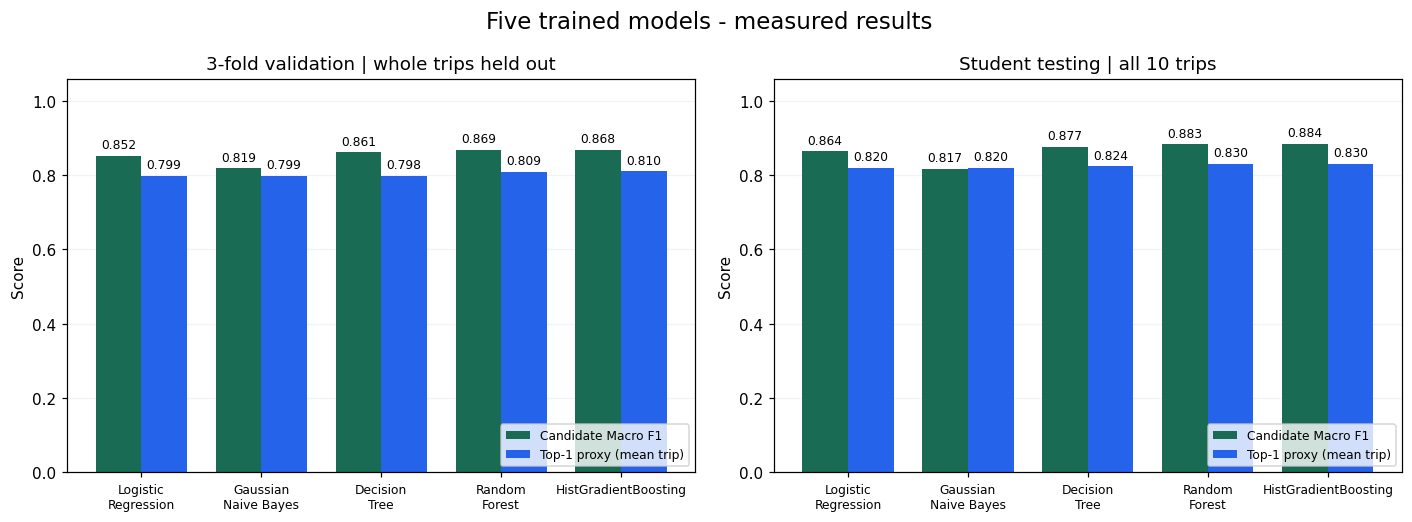

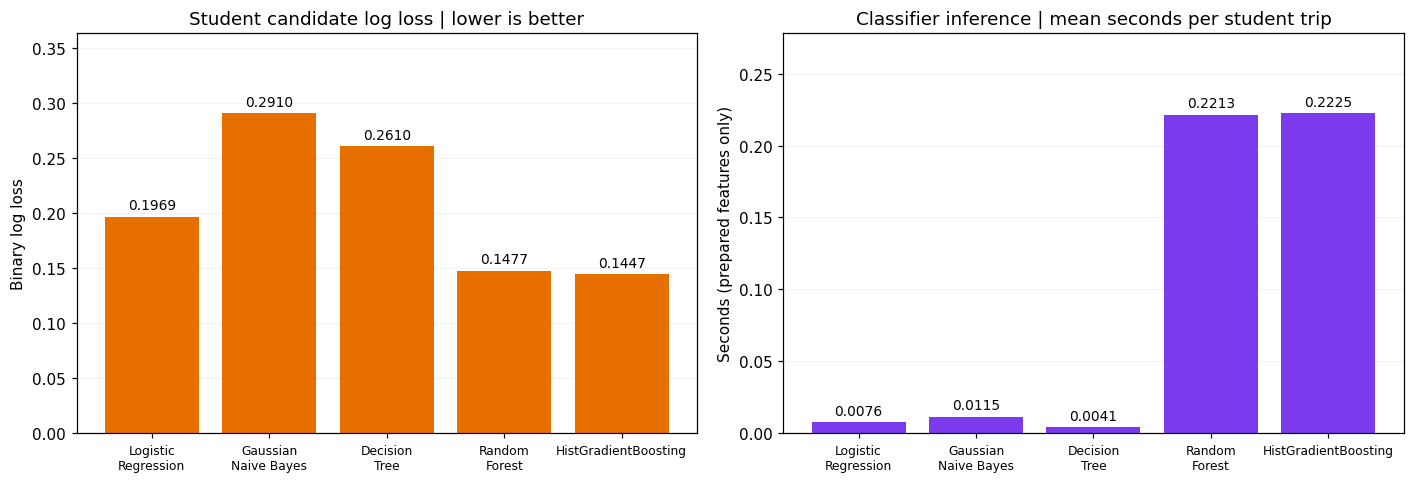

In [6]:
score_fig, efficiency_fig = comparison_figures(ROOT)
display(score_fig)
display(efficiency_fig)
plt.close(score_fig)
plt.close(efficiency_fig)

HGB narrowly leads CV Top-1; Random Forest narrowly leads CV candidate Macro F1.
The differences are small relative to fold variability. Classifier time excludes
raw loading, candidate generation, maps and network communication.

### 6. Actual candidate confusion matrices

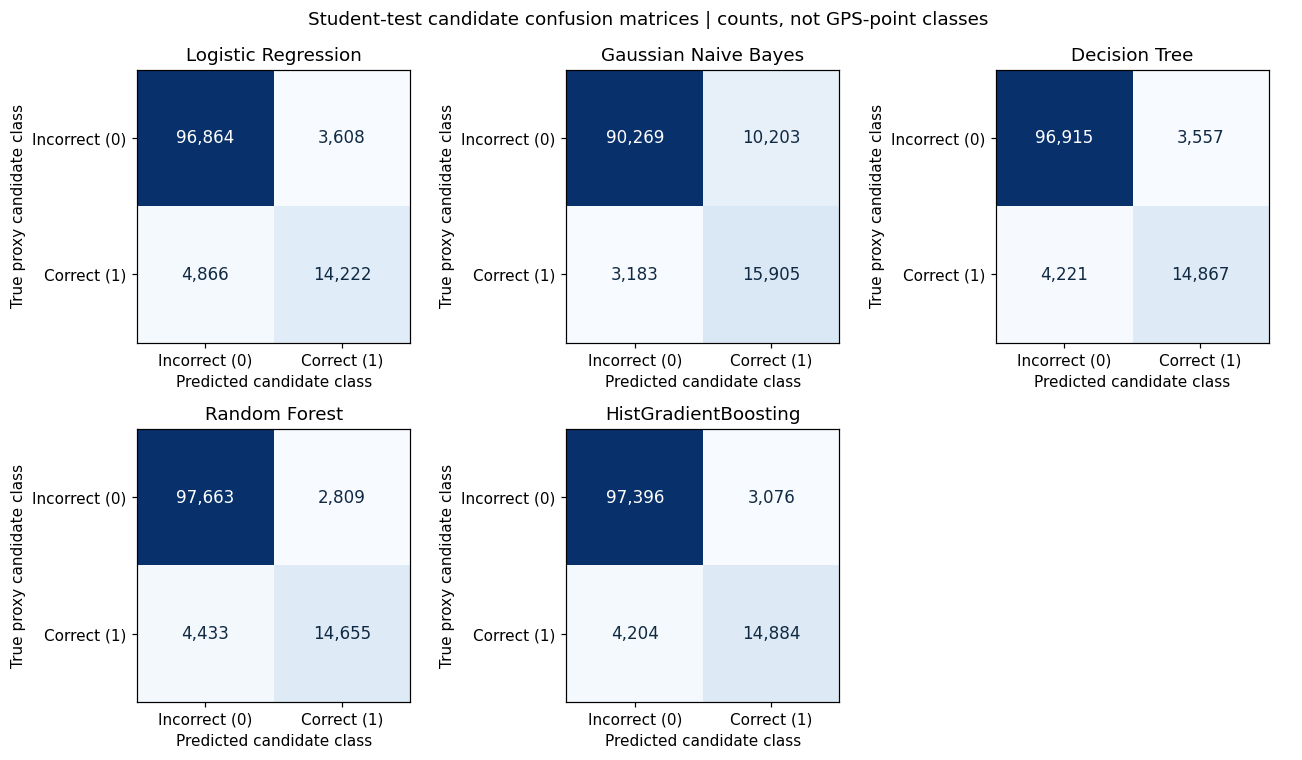

In [7]:
confusion = confusion_figure(ROOT)
display(confusion)
plt.close(confusion)

These matrices classify **candidate correctness (0/1)** against derived labels.
They do not classify the GPS points into five model classes.

### 7. Run the saved classifiers now on one trip
This cell performs a fresh `predict_proba` pass for each trained model on the
prepared feature tensor. It then displays actual selected arc IDs.
It does not rerun training or use reference labels as input features.

In [8]:
prediction_rows, fresh_scores, prediction_block = fresh_predictions(TRIP_ID, ROOT)
fresh_output = fresh_scores.copy()
fresh_output['model'] = fresh_output['model'].map(NAMES)
display(fresh_output.round(5))
display(prediction_rows.head(12))

,model,observations,aligned_points,trip_top1_proxy,fresh_classifier_seconds
0,Logistic Regression,2503,2503,0.91730,0.04204
1,Gaussian Naive Bayes,2503,2503,0.92209,0.00747
2,Decision Tree,2503,2503,0.92449,0.00637
3,Random Forest,2503,2503,0.92289,0.08622
4,HistGradientBoosting,2503,2503,0.92409,0.08629


,GPS row,reference proxy,logistic,naive_bayes,decision_tree,random_forest,hist_boost
0,0,17630,17630,17630,17630,17630,17630
1,1,17630,17630,17630,17630,17630,17630
2,2,17630,17630,17630,17630,17630,17630
3,3,17633,17633,17633,17633,17633,17633
4,4,17633,17633,17633,17633,17633,17633
5,5,211,211,211,211,211,211
6,6,211,211,211,211,211,211
7,7,211,211,211,211,211,211
8,8,211,211,211,211,211,211
9,9,17638,17638,17638,17638,17638,17638


### 8. One observation: candidate probabilities → chosen road
The selected model's actual candidate scores explain how its highest-scoring
candidate becomes one predicted road arc for a GPS row.

In [9]:
import joblib
from threadpoolctl import threadpool_limits
selected = joblib.load(ROOT / 'artifacts/selected.joblib')
mask = prediction_block['valid'][observation]
with threadpool_limits(limits=1):
    raw_scores = selected['model'].predict_proba(prediction_block['X'][observation, mask])[:, 1]
candidate_scores = pd.DataFrame({
    'arc_id': prediction_block['ids'][observation, mask],
    'distance_m': prediction_block['X'][observation, mask, 0],
    'raw_candidate_probability': raw_scores,
    'normalized_score': raw_scores.clip(1e-9) / raw_scores.clip(1e-9).sum()
}).sort_values('raw_candidate_probability', ascending=False)
print('Model:', NAMES[run['selected_untuned_model']], '| GPS observation:', observation)
display(candidate_scores.round(5))
print('Chosen arc ID:', int(candidate_scores.iloc[0].arc_id))

Model: HistGradientBoosting | GPS observation: 0


,arc_id,distance_m,raw_candidate_probability,normalized_score
0,17630,6.114290,0.58778,0.67101
1,17634,6.114290,0.25533,0.29149
2,17635,27.673401,0.01258,0.01437
3,17668,27.673401,0.01228,0.01402
5,17633,46.000561,0.00444,0.00507
4,212,46.000561,0.00354,0.00405


Chosen arc ID: 17630


## Checks
Verify the five models, whole-trip fold membership, and fresh predictions
against the saved per-trip measurements.

In [10]:
folds = json.loads((ROOT / 'artifacts/cv_splits.json').read_text())
assert len(comparison) == 5 and len(run['models']) == 5
for fold in folds:
    assert set(fold['train_trips']).isdisjoint(fold['validation_trips'])
held_out = [trip for fold in folds for trip in fold['validation_trips']]
assert len(held_out) == len(set(held_out)) == 80
recorded = pd.read_csv(ROOT / 'artifacts/classifier_sequence_comparison.csv', dtype={'trip_id': str})
recorded = recorded[recorded.trip_id == TRIP_ID].set_index('model')
for row in fresh_scores.itertuples():
    assert np.isclose(row.trip_top1_proxy, recorded.loc[row.model, 'top1_accuracy_proxy'])
    assert row.observations == len(gps)
print('PASS: five trained models; whole-trip folds; 80 unique held-out trips.')
print('PASS: fresh predictions match the saved trip scores for all five models.')
print('Original five-model comparison checked. Completed later stages appear below.')

PASS: five trained models; whole-trip folds; 80 unique held-out trips.
PASS: fresh predictions match the saved trip scores for all five models.
Original five-model comparison checked. Completed later stages appear below.


## Completed optimisation and sequence decoding
The following outputs were generated after the original five-model comparison.

### 9. Bayesian optimisation: actual 15-trial search
Three random startup trials and twelve adaptive TPE trials used the same
three training-trip folds. No evaluator examples entered the search.

,number,value,state
0,0,0.811045,COMPLETE
1,1,0.808350,COMPLETE
2,2,0.809574,COMPLETE
3,3,0.808916,COMPLETE
4,4,0.810338,COMPLETE
5,5,0.810834,COMPLETE
6,6,0.808959,COMPLETE
7,7,0.807208,COMPLETE
8,8,0.806993,COMPLETE
9,9,0.810962,COMPLETE


Best hyperparameters: {'max_iter': 100, 'max_leaf_nodes': 63, 'learning_rate': 0.048015180105304096, 'l2_regularization': 0.3890112181435344, 'min_samples_leaf': 15}
Best CV mean-trip Top-1 proxy: 0.811061
Tuned student candidate Macro F1: 0.883891
Tuned student mean-trip Top-1 proxy: 0.83055


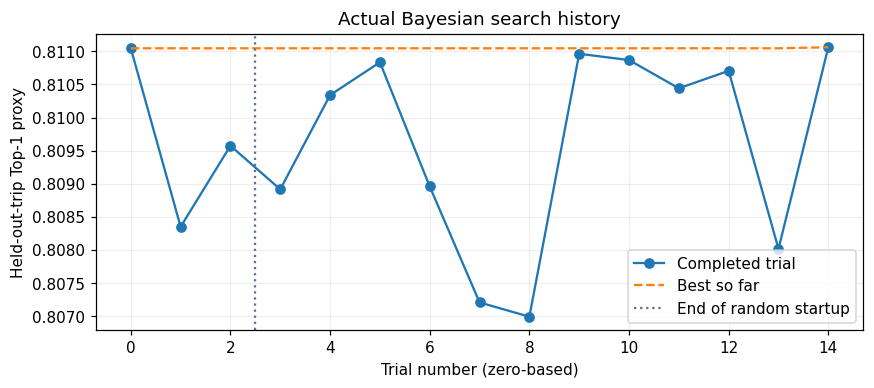

In [11]:
tuning = json.loads((ROOT / 'artifacts/tuning_summary.json').read_text())
trials = pd.read_csv(ROOT / 'artifacts/optimization_trials.csv')
display(trials[['number', 'value', 'state']])
print('Best hyperparameters:', tuning['best_parameters'])
print('Best CV mean-trip Top-1 proxy:', round(tuning['best_cv_top1_macro_trip_proxy'], 6))
print('Tuned student candidate Macro F1:', round(tuning['student_test']['macro_f1'], 6))
print('Tuned student mean-trip Top-1 proxy:', round(tuning['student_test']['top1_macro_trip_proxy'], 6))
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(trials.number, trials.value, 'o-', label='Completed trial')
ax.plot(trials.number, trials.value.cummax(), '--', label='Best so far')
ax.axvline(2.5, color='#64748b', linestyle=':', label='End of random startup')
ax.set(xlabel='Trial number (zero-based)', ylabel='Held-out-trip Top-1 proxy', title='Actual Bayesian search history')
ax.legend(); ax.grid(alpha=.2); plt.show()

### 10. Classifier versus HMM/Viterbi on all student-test trips
Hidden states are candidate directed road arcs. The decoder combines
classifier scores with feasible directed-road transitions. Gaps, missing
candidates and impossible transitions create explicit route breaks.

,top1_accuracy_proxy,strict_adjacency_rate,arc_set_f1,sampled_arc_edit_similarity
stage,,,,
classifier,0.83055,0.89949,0.79801,0.45369
hmm,0.87186,0.96077,0.88388,0.68403


stage,classifier,hmm
trip_id,,
00000000,0.92449,0.94567
00000007,0.89882,0.90620
00000009,0.81030,0.88179
00000040,0.87012,0.91185
00000052,0.93130,0.99237
00000056,0.86247,0.91474
00000065,0.78255,0.81250
00000076,0.78197,0.87685
00000077,0.62542,0.63334


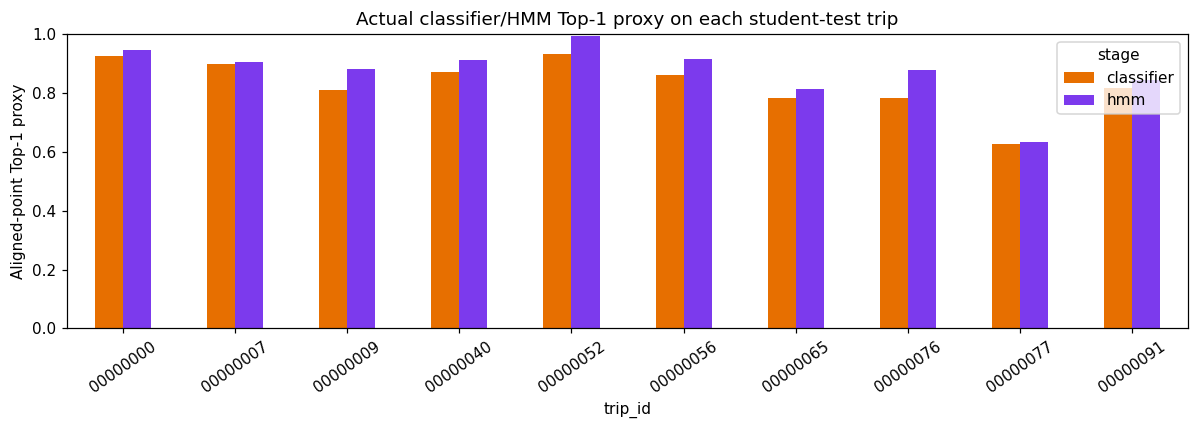

In [12]:
routes = pd.read_csv(ROOT / 'artifacts/route_evaluation.csv', dtype={'trip_id': str})
selected_routes = routes[routes.model == 'selected']
summary = selected_routes.groupby('stage')[['top1_accuracy_proxy', 'strict_adjacency_rate', 'arc_set_f1', 'sampled_arc_edit_similarity']].mean()
display(summary.round(5))
comparison_by_trip = selected_routes.pivot(index='trip_id', columns='stage', values='top1_accuracy_proxy')
display(comparison_by_trip.round(5))
comparison_by_trip.plot.bar(figsize=(11, 4), color=['#e76f00', '#7c3aed'], ylim=(0, 1), rot=35)
plt.title('Actual classifier/HMM Top-1 proxy on each student-test trip')
plt.ylabel('Aligned-point Top-1 proxy'); plt.tight_layout(); plt.show()

### 11. Frozen model and independent verification
The manifest was written before evaluator inputs were imported.
Runtime checks verify its model and inference-source checksums.

In [13]:
frozen = json.loads((ROOT / 'artifacts/final/model_manifest.json').read_text())
verified = json.loads((ROOT / 'artifacts/development_verification.json').read_text())
display(pd.DataFrame([{'model': frozen['model_name'], 'frozen_utc': frozen['frozen_utc'],
                       'trained_partition': frozen['trained_partition'], 'model_sha256': frozen['model_sha256']}]))
print('Directed route-part connectivity verified:', verified['reconstructed_parts_are_directed_connected'])
print('Whole-trip CV verification:', verified['unique_validation_trips'], 'unique held-out training trips')

,model,frozen_utc,trained_partition,model_sha256
0,hist_boost_tuned,2026-11-18T07:15:26.136400+00:00,train,5cb6500bf65c7edb28b71592fc7243e1a00329683317d8...


Directed route-part connectivity verified: True
Whole-trip CV verification: 80 unique held-out training trips


### 12. Final evaluator run: all ten trips through HTTP
These results were obtained only after the model/configuration freeze.
They were not used to alter the model, thresholds or decoder. Scores are
reference-alignment proxies, including the weaker result on trip 00000015.

In [14]:
final_receipt = json.loads((ROOT / 'artifacts/evaluator_api_smoke.json').read_text())
final_rows = pd.DataFrame([{'trip_id': r['trip_id'], 'HTTP': r['http_status'],
    'GPS observations': r['observations'], 'classifier Top-1 proxy': r['metrics']['classifier']['top1_accuracy_proxy'],
    'HMM Top-1 proxy': r['metrics']['hmm']['top1_accuracy_proxy'],
    'alignment coverage': r['metrics']['hmm']['alignment_coverage'], 'HTTP seconds': r['http_seconds']}
    for r in final_receipt['results']])
display(final_rows.round(5))
assert len(final_rows) == 10 and final_rows.HTTP.eq(200).all()
assert final_receipt['model_sha256'] == frozen['model_sha256']
print('PASS: all ten evaluator requests succeeded with the frozen model.')

,trip_id,HTTP,GPS observations,classifier Top-1 proxy,HMM Top-1 proxy,alignment coverage,HTTP seconds
0,00000015,200,6854,0.51809,0.48030,1.0,8.18380
1,00000017,200,1346,0.86627,0.90045,1.0,3.52168
2,00000023,200,458,0.91921,0.93450,1.0,0.75354
3,00000030,200,654,0.75535,0.83028,1.0,1.36600
4,00000049,200,2642,0.96442,0.98297,1.0,4.30217
5,00000059,200,1031,0.91077,0.94665,1.0,1.90345
6,00000067,200,916,0.80568,0.84607,1.0,1.31260
7,00000073,200,1144,0.90734,0.95979,1.0,1.76262
8,00000087,200,1399,0.92638,0.99214,1.0,3.99954
9,00000094,200,3230,0.76749,0.81610,1.0,4.94626


PASS: all ten evaluator requests succeeded with the frozen model.


### 13. Send a fresh request to this backend laptop
Keep `START_BACKEND.cmd` running. Change `EVALUATOR_TRIP_ID` to any ID
returned by `/trips`, then rerun this cell. It performs actual inference.

In [15]:
import urllib.request
opener = urllib.request.build_opener(urllib.request.ProxyHandler({}))
API_BASE = 'http://127.0.0.1:8766'
with opener.open(API_BASE + '/health', timeout=20) as response:
    health = json.load(response)
with opener.open(API_BASE + '/trips', timeout=20) as response:
    evaluator_ids = json.load(response)['trips']
EVALUATOR_TRIP_ID = evaluator_ids[0]  # Choose any of the ten IDs here.
request = urllib.request.Request(API_BASE + '/match',
    data=json.dumps({'trip_id': EVALUATOR_TRIP_ID}).encode(),
    headers={'Content-Type': 'application/json'}, method='POST')
with opener.open(request, timeout=300) as response:
    live_result = json.load(response)
print('HTTP 200 | Request:', live_result['request_id'])
print('Trip:', live_result['trip_id'], '| GPS observations:', live_result['observations'])
print('Frozen model SHA256:', live_result['model_sha256'])
display(pd.DataFrame([{'stage': stage, **{key: live_result['metrics'][stage][key]
    for key in ['top1_accuracy_proxy', 'alignment_coverage', 'strict_adjacency_rate', 'arc_set_f1']}}
    for stage in ['classifier', 'hmm']]).round(5))
display(pd.DataFrame({'GPS row': range(12), 'classifier arc': live_result['classifier_arc_ids'][:12],
                      'HMM arc': live_result['prediction_arc_ids'][:12]}))

HTTP 200 | Request: 440a1f8475b24140883711e290063c8f
Trip: 00000015 | GPS observations: 6854
Frozen model SHA256: 5cb6500bf65c7edb28b71592fc7243e1a00329683317d8f0a14cbb883e173f11


,stage,top1_accuracy_proxy,alignment_coverage,strict_adjacency_rate,arc_set_f1
0,classifier,0.51809,1.0,0.91989,0.57267
1,hmm,0.48030,1.0,0.95783,0.57965


,GPS row,classifier arc,HMM arc
0,0,1258,1258
1,1,3035,3035
2,2,1258,3035
3,3,3035,3035
4,4,3035,3035
5,5,3035,3035
6,6,1258,1258
7,7,1258,1258
8,8,3035,3035
9,9,1258,3035


### 14. Live Folium map: GPS, roads and predicted route
This map comes from the backend request above. Reference route labels
are not included. The GPS/road layers use locally hosted Leaflet assets;
only the optional OpenStreetMap background tiles need internet.

In [16]:
from IPython.display import IFrame
display(IFrame(src=API_BASE + live_result['map_path'], width='100%', height=580))

### 15. Development Folium map with reference layer
This separate local view uses the student-test trip, as required for the
technical report. It is not exposed in the evaluator API/UI.

In [17]:
from IPython.display import HTML
import html
development_html = (ROOT / 'artifacts/maps/00000000.html').read_text(encoding='utf-8')
development_html = development_html.replace('../../frontend/vendor/leaflet', API_BASE + '/assets/leaflet')
display(HTML('<iframe title="Student development Folium map" style="width:100%;height:580px;border:0" srcdoc="'
             + html.escape(development_html, quote=True) + '"></iframe>'))

C:\Users\Jignas\Desktop\ml-hack\.venv\Lib\site-packages\IPython\core\display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


## Demonstration handoff
This machine hosts the model, HMM, evaluator files and API.
Laptop 2 can open `http://10.1.24.198:8766/ui/` on the same network.
For a separately served frontend, use the supplied frontend ZIP.
Backend request IDs and aggregate scores are in `artifacts/backend.log`.
A physical second-laptop rehearsal and receiving-terminal screenshots
still need to be captured by the team; local HTTP checks do not prove them.